## Fetching Building Footprints

In [1]:
import osmnx as ox

# 1. Set a descriptive user agent (OSM servers block default/empty python-requests headers)
ox.settings.user_agent = "dsc180a_property_footprint_project_ucsd"

# 2. Switch from the default Overpass endpoint to a reliable mirror
# (Kumi Systems or Main Overpass API instance)
ox.settings.overpass_endpoint = "https://overpass.kumi.systems/api"

# Optional: increase timeout if fetching dense areas (default is 180s)
ox.settings.requests_timeout = 300

# 3. Now run your query
gdf = ox.features_from_address(
    "92105, San Diego, CA, USA", 
    tags={"building": True}, 
    dist=2000
)

# 4. Filter for polygon footprints
gdf = gdf[gdf.geometry.type.isin(["Polygon", "MultiPolygon"])]

print(f"Retrieved {len(gdf)} buildings.")
gdf.head()

Retrieved 6830 buildings.


geometry  \
element  id                                                            
relation 9275383   POLYGON ((-117.11536 32.75286, -117.11536 32.7...   
         13117720  POLYGON ((-117.10186 32.75036, -117.10186 32.7...   
         19893234  MULTIPOLYGON (((-117.09077 32.74913, -117.0908...   
way      31800447  POLYGON ((-117.11114 32.75504, -117.11114 32.7...   
         31800492  POLYGON ((-117.11198 32.72437, -117.11198 32.7...   

                  addr:state    building  ele gnis:feature_id  \
element  id                                                     
relation 9275383         NaN         yes  NaN             NaN   
         13117720        NaN         yes  NaN             NaN   
         19893234        NaN         yes  NaN             NaN   
way      31800447        NaN  commercial  NaN             NaN   
         31800492        NaN   education  NaN             NaN   

                              name  \
element  id                          
relation 9275383               NaN   
         13117720              NaN   
         19893234  Gloria's Beauty   
way      31800447              NaN   
         31800492              NaN   

                                                              source  \
element  id                                                            
relation 9275383                                                 NaN   
         13117720                                                NaN   
         19893234                                                NaN   
way      31800447  SanGIS Footprints_Nonresidential_SD public dom...   
         31800492  SanGIS Footprints_Nonresidential_SD public dom...   

                   addr:city addr:country addr:housenumber  ... height  \
element  id                                                 ...          
relation 9275383   San Diego           US             3615  ...    NaN   
         13117720        NaN          NaN              NaN  ...    NaN   
         19893234        NaN          NaN              NaN  ...    NaN   
way      31800447  San Diego           US             3815  ...    NaN   
         31800492        NaN          NaN              NaN  ...    NaN   

                  building:units baseball construction:amenity  bin  \
element  id                                                           
relation 9275383             NaN      NaN                  NaN  NaN   
         13117720            NaN      NaN                  NaN  NaN   
         19893234            NaN      NaN                  NaN  NaN   
way      31800447            NaN      NaN                  NaN  NaN   
         31800492            NaN      NaN                  NaN  NaN   

                  hairdresser man_made community_centre ceremonial_gate  \
element  id                                                               
relation 9275383          NaN      NaN              NaN             NaN   
         13117720         NaN      NaN              NaN             NaN   
         19893234         NaN      NaN              NaN             NaN   
way      31800447         NaN      NaN              NaN             NaN   
         31800492         NaN      NaN              NaN             NaN   

                           type  
element  id                      
relation 9275383   multipolygon  
         13117720  multipolygon  
         19893234  multipolygon  
way      31800447           NaN  
         31800492           NaN  

[5 rows x 113 columns]

## Mapping and Visualizing Footprints

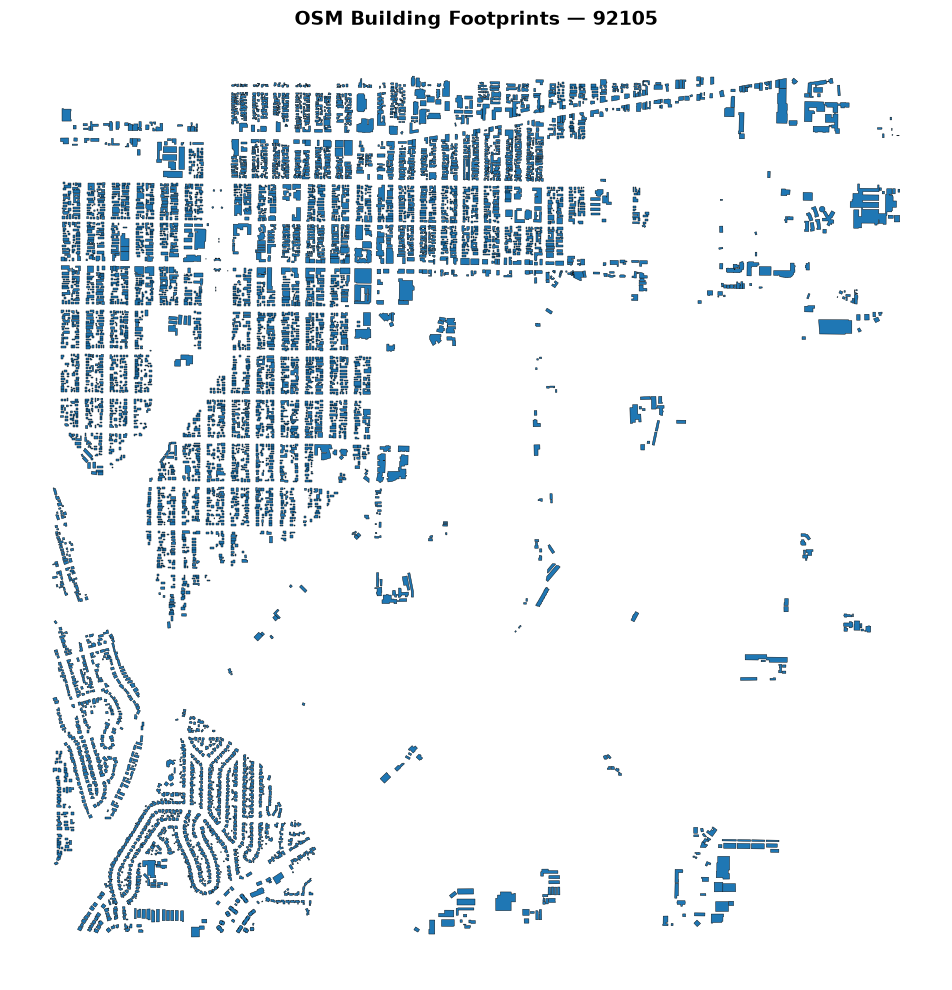

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    ax=ax, 
    edgecolor="black", 
    linewidth=0.3, 
)

ax.set_title("OSM Building Footprints — 92105", fontsize=14, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Transformations

In [3]:
# Turn units to meters
gdf_utm = gdf.to_crs(epsg=32611)

#### Buffer All Buildings By -2 m

In [4]:
# Buffer all buildings by -2m
gdf_neg2 = gdf_utm.copy()
gdf_neg2["geometry"] = gdf_utm.geometry.buffer(-2)

In [5]:
empty_count2 = gdf_neg2.is_empty.sum()
print("Buildings With Empty Geometries (-2m Buffer):", empty_count2)

Buildings With Empty Geometries (-2m Buffer): 180


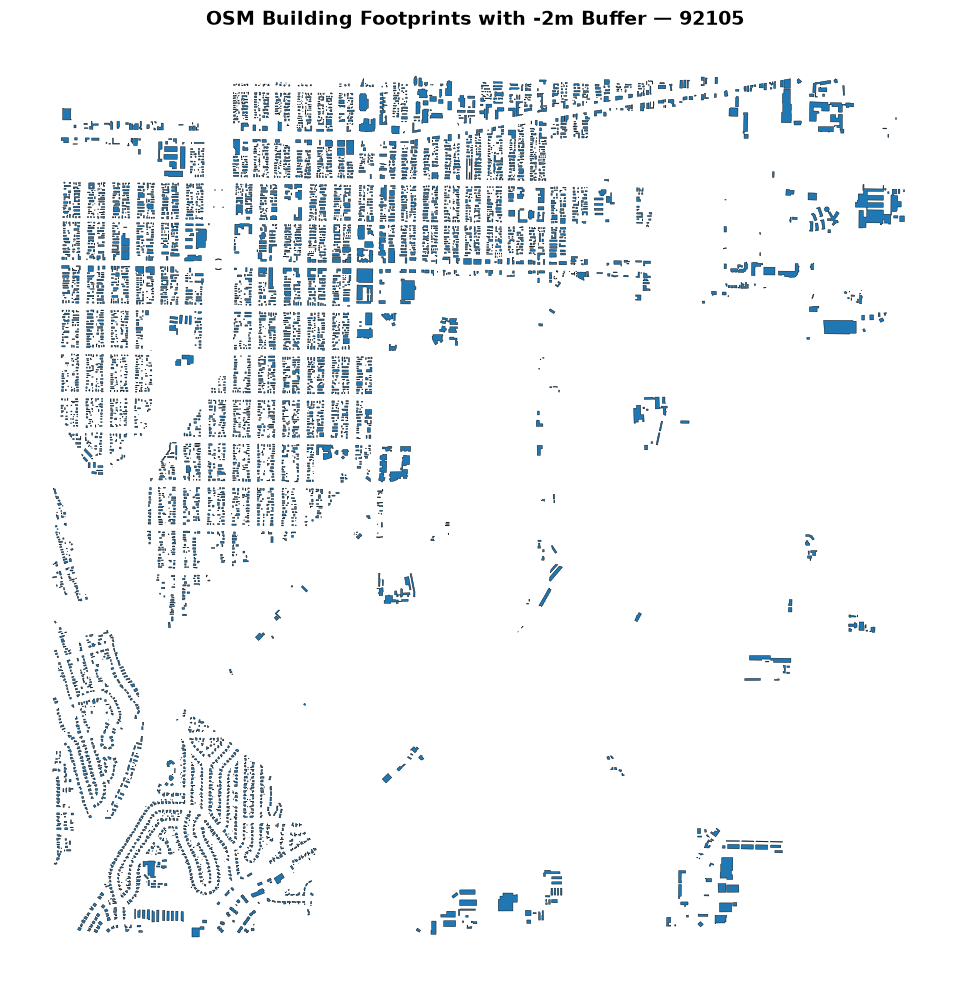

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))

gdf_neg2.plot(
    ax=ax, 
    edgecolor="black", 
    linewidth=0.3, 
)

ax.set_title("OSM Building Footprints with -2m Buffer — 92105 ", fontsize=14, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

#### Buffer All Buildings By -5 m

In [7]:
# Buffer all buildings by -5m
gdf_neg5 = gdf_utm.copy()
gdf_neg5["geometry"] = gdf_utm.geometry.buffer(-5)

In [8]:
empty_count5 = gdf_neg5.is_empty.sum()
print("Buildings With Empty Geometries (-5m Buffer):", empty_count5)

Buildings With Empty Geometries (-5m Buffer): 4042


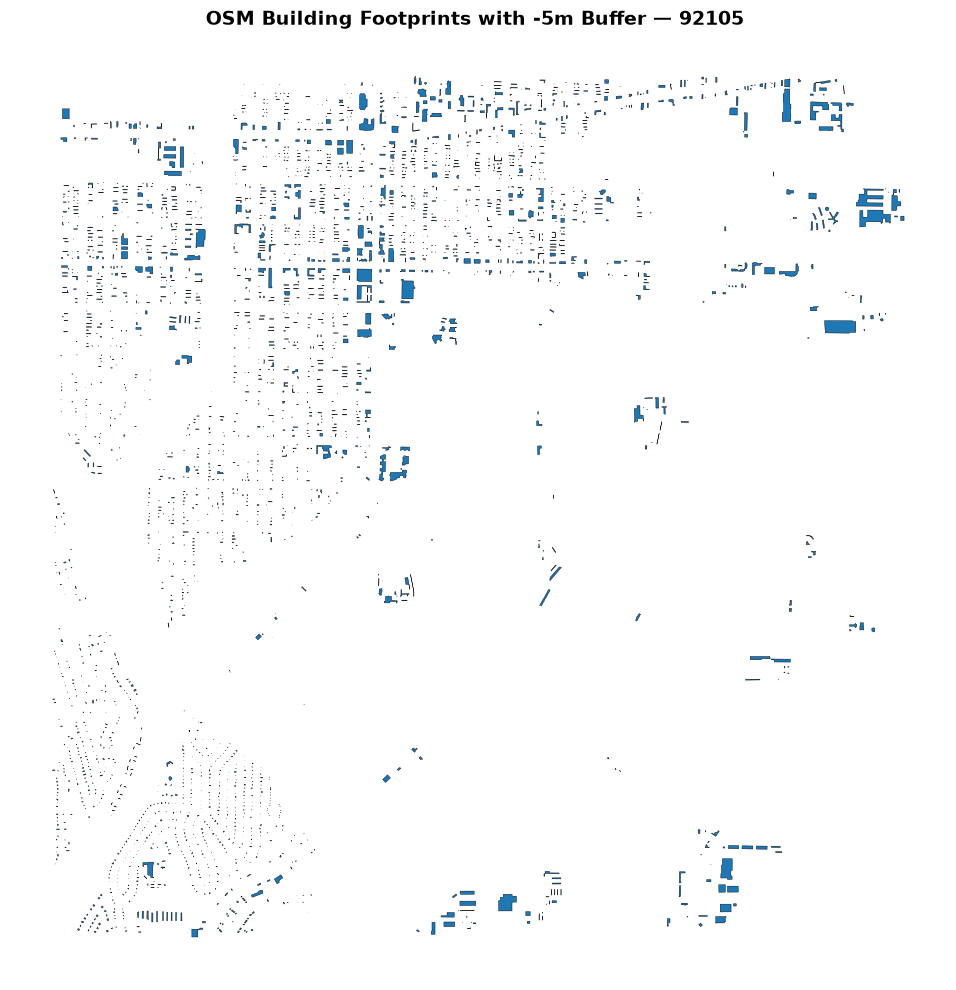

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))

gdf_neg5.plot(
    ax=ax, 
    edgecolor="black", 
    linewidth=0.3, 
)

ax.set_title("OSM Building Footprints with -5m Buffer — 92105 ", fontsize=14, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()